In [0]:
# Load the cleaned ERA5 dataset from Delta Lake
df = spark.table("era5_project.silver.era5_clean")

# Select the columns required for the analysis
df_analysis = df.select(
    "pressure_level",
    "temperature_c"
)

display(df_analysis.limit(10))

pressure_level,temperature_c
700,1.530020000000036
300,-39.46568999999997
150,-56.38636999999997
1000,16.309600000000046
925,11.36474000000004
100,-63.60759999999999
150,-52.89236999999997
700,-2.9251499999999737
100,-63.30854999999997
250,-51.362419999999986


In [0]:
from pyspark.sql import functions as F
# Map: select the key and value needed for analysis
mapped_df = (
    df.select(
        F.col("pressure_level"),
        F.col("temperature_c")
    )
    .filter(
        F.col("pressure_level").isNotNull() &
        F.col("temperature_c").isNotNull()
    )
)
print(mapped_df)

DataFrame[pressure_level: int, temperature_c: double]


In [0]:

try:
    data = [
        (1000, 15.0),
        (1000, 14.5),
        (850, 6.5),
        (850, 7.0)
    ]

    rdd = spark.sparkContext.parallelize(data)

    mapped_rdd = rdd.map(
        lambda row: (row[0], (row[1], 1))
    )

    reduced_rdd = mapped_rdd.reduceByKey(
        lambda a, b: (a[0] + b[0], a[1] + b[1])
    )

    result = reduced_rdd.mapValues(
        lambda x: x[0] / x[1]
    )

    print(result.collect())

except Exception as e:
    print("RDD-based MapReduce attempt failed.")
    print(type(e).__name__)
    print(str(e))

RDD-based MapReduce attempt failed.
PySparkAttributeError
[JVM_ATTRIBUTE_NOT_SUPPORTED] Attribute `sparkContext` is not available on Standard access mode or Serverless compute because it requires direct access to the Spark driver JVM. Switch to Dedicated access mode to use it.


In [0]:
# Reduce: aggregate temperature statistics by pressure level
result_df = (
    mapped_df
    .groupBy("pressure_level")
    .agg(
        F.sum("temperature_c").alias("total_temperature_c"),
        F.count("temperature_c").alias("observation_count"),
        F.avg("temperature_c").alias("average_temperature_c")
    )
    .orderBy("pressure_level")
)

display(result_df)

pressure_level,total_temperature_c,observation_count,average_temperature_c
50,-2303623.7109400043,39076,-58.952393053024984
100,-2393102.106369977,39076,-61.24224860195457
150,-2215129.058930003,39076,-56.68771263512138
200,-2100633.3220999897,39076,-53.75763440730857
250,-1949620.8239500008,39076,-49.89305005502101
300,-1678160.764620004,39076,-42.94607341130116
400,-1112229.7837000107,39076,-28.463245565052993
500,-653571.1394199992,39076,-16.725640787695752
600,-293170.23354999686,39076,-7.502565092383992
700,-14026.851839999135,39076,-0.35896334937043545


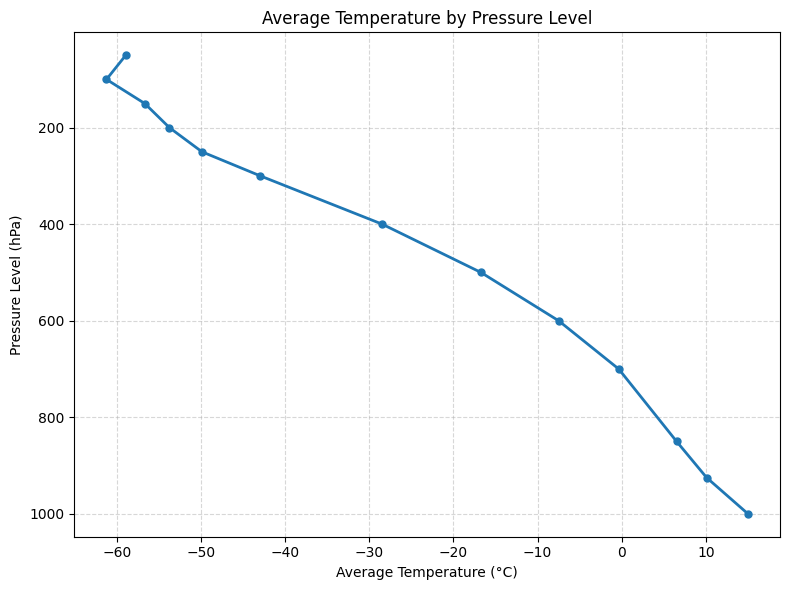

In [0]:
import matplotlib.pyplot as plt

# Prepare the results for visualization
plot_df = (
    result_df
    .select("pressure_level", "average_temperature_c")
    .orderBy("pressure_level")
    .toPandas()
)

# Create the line chart
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    plot_df["average_temperature_c"],
    plot_df["pressure_level"],
    marker="o",
    linewidth=2,
    markersize=5
)

# Display lower pressure levels at the top
ax.invert_yaxis()

ax.set_title("Average Temperature by Pressure Level")
ax.set_xlabel("Average Temperature (°C)")
ax.set_ylabel("Pressure Level (hPa)")

ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [0]:
from pyspark.sql import functions as F

# Load the cleaned ERA5 Delta table
df = spark.table("era5_project.silver.era5_clean")

# Filter pressure level at 1000 hPa
# Convert UTC timestamps to Auckland local time
monthly_temp_df = (
    df
    .filter(F.col("pressure_level") == 1000)
    .withColumn(
        "local_time",
        F.from_utc_timestamp(
            F.col("valid_time"),
            "Pacific/Auckland"
        )
    )
    .withColumn("month_num", F.month("local_time"))
    .groupBy("month_num")
    .agg(
        F.avg("temperature_c").alias("average_temperature_c"),
        F.count("*").alias("observation_count")
    )
    .orderBy("month_num")
)

display(monthly_temp_df)

month_num,average_temperature_c,observation_count
1,18.489882875074716,3346
2,19.00061265072089,3052
3,17.83817780764634,3348
4,16.32165013580251,3240
5,14.488874677419375,3348
6,12.734389885802488,3240
7,11.699820209080102,3348
8,11.633149118876979,3348
9,12.414298823347758,3238
10,13.42021569789082,3224


Databricks visualization. Run in Databricks to view.

In [0]:
from pyspark.sql import functions as F

df = spark.table("era5_project.silver.era5_clean")

annual_weather_df = (
    df
    .filter(F.col("pressure_level") == 1000)
    .withColumn(
        "local_time",
        F.from_utc_timestamp(
            F.col("valid_time"),
            "Pacific/Auckland"
        )
    )
    .withColumn("year", F.year("local_time"))
    .filter(F.col("year").between(2000, 2026))
    .groupBy("year")
    .agg(
        F.avg("temperature_c").alias("average_temperature_c"),
        F.avg("relative_humidity").alias("average_relative_humidity"),
        F.count("*").alias("observation_count")
    )
    .orderBy("year")
)

display(annual_weather_df)

year,average_temperature_c,average_relative_humidity,observation_count
2000,14.684804596443254,75.40472383173747,1462
2001,14.8313331712329,76.98314746917787,1460
2002,14.742232623287693,74.90822423767128,1460
2003,14.753135075342502,76.26657892671231,1460
2004,14.189053114754119,75.31607107240454,1464
2005,15.143824835616451,75.56624268835614,1460
2006,14.488680493150706,75.42485930410973,1460
2007,14.795400486301384,76.46012504041096,1460
2008,14.876072247267805,75.76778049112019,1464
2009,14.4639212945206,75.2636371952054,1460


Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.